## Rouse polymer

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os
from viz_util import overdamped_langevin as lgv

### Recovering the Arrhenius exit time

#### Checking the equilibrium distribution for a harmonic potential

In [2]:
k = 3
gamma = 0.5
dt = 0.01 * gamma / k   # choose much smaller than characteristic time
sim = lgv.OverdampedHarmonicLangevin(
    tau=500000*dt, dim=1, N=1, dt=dt,
    T=1.0, F=lambda r: -k * r,
    gamma = gamma, nskip = 10
)
sim.generate()

empirical Var(r) = 0.3283469173095977   expected = 0.3333333333333333


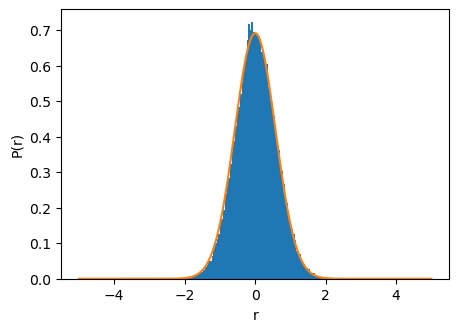

In [3]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

xs = np.linspace(-5, 5, 500)
var = sim.kB * sim.T_bath / k       # OU stationary variance for F = -k r
dist = np.exp(-xs**2/(2*var)) / np.sqrt(2*np.pi*var)

# discard burn-in (a few relaxation times tau_relax = gamma/k)
burn = int(5 * gamma / k / sim.dt)
ax.hist(sim.r[burn:,0,0].flatten(), bins=100, density=True)
# ax.hist(sim.r[-1,0,:].flatten(), bins=100, density=True)
ax.plot(xs, dist)
ax.set_xlabel("r"); ax.set_ylabel("P(r)")
print("empirical Var(r) =", sim.r[burn:,0,0].var(), "  expected =", var)

### A simple potential with well and barrier 

In [72]:
# Double-well potential: 1/(100|r|) keeps r > 0, Gaussian creates the barrier,
# 0.01 r^2 confines at large r.
args = (100, 1.0, 0.48, 0.01)


left well  : r=0.010, U=0.360, ω_well=0.896
barrier    : r=1.009,  U=1.010,  ω_bar =1.436
ΔU = 0.650


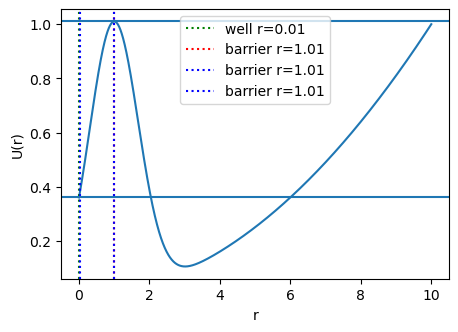

In [73]:
def U(x, *args):
    a, b, c, d = args
    # return 1.0 / np.abs(a * x) + np.exp(-(x - b) ** 2 / (2 * c)) + d * x ** 2
    return np.exp(-(x - b) ** 2 / (2 * c)) + d * x ** 2


def F(x, *args):
    """Analytic force F = -dU/dx (only valid for x > 0)."""
    a, b, c, d = args
    # return 1.0 / (a * x ** 2) + (x - b) / c * np.exp(-(x - b) ** 2 / (2 * c)) - 2 * d * x
    return (x - b) / c * np.exp(-(x - b) ** 2 / (2 * c)) - 2 * d * x


# --- locate left well, barrier; compute ΔU and curvatures ---
xs = np.linspace(1e-2, 10, 5000)
U_vals = U(xs, *args)

left = xs < 2.0
right = xs > 2.0
i_well = np.argmin(U_vals[left])
i_barrier = (np.argmax(U_vals[left]) if False
             else np.argmax(U_vals * ((xs > xs[left][i_well]) & (xs < 3.5))))

x_well, U_well = xs[left][i_well], U_vals[left][i_well]
x_bar,  U_bar = xs[i_barrier],   U_vals[i_barrier]
dU = U_bar - U_well
x_bar_a = 0.05
x_bar_b = x_bar

# numerical curvatures


def d2U(x):
    h = 1e-5
    return (U(x + h, *args) - 2 * U(x, *args) + U(x - h, *args)) / h ** 2


omega_well = np.sqrt(d2U(x_well))     # >0
omega_bar = np.sqrt(-d2U(x_bar))      # |U''| at the saddle

print(f"left well  : r={x_well:.3f}, U={U_well:.3f}, ω_well={omega_well:.3f}")
print(f"barrier    : r={x_bar:.3f},  U={U_bar:.3f},  ω_bar ={omega_bar:.3f}")
print(f"ΔU = {dU:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.plot(xs, U_vals)
ax.axvline(x_well, color="g", ls=":", label=f"well r={x_well:.2f}")
ax.axvline(x_bar,  color="r", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_a,  color="b", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_b,  color="b", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axhline(U_well)
ax.axhline(U_bar)
ax.set_xlabel("r")
ax.set_ylabel("U(r)")
ax.legend()

#### Simulating Langevin under that potential

In [60]:
# --- parameter selection -------------------------------------------------
# 1) Temperature: ΔU/(kBT) in [3, 7] is the Arrhenius sweet spot --- escape
#    is rare enough to be exponentially distributed, frequent enough to
#    collect statistics in reasonable wall-clock time.
T_bath = 0.28                    # -> ΔU/T ≈ 4.6 here
gamma  = 0.3
kB     = 1.0

# 2) Time step: needs to satisfy BOTH
#       dt < (1/10) * γ / max|U''|         (drift stability)
#       √(2 kBT/γ * dt) << min feature size (noise step << well width)
relax_well = gamma / d2U(x_well)              # γ / U''(well)
relax_bar  = gamma / abs(d2U(x_bar))          # γ / |U''(barrier)|
dt_drift   = 0.01 * min(relax_well, relax_bar)
noise_step_target = 0.1 * (x_bar - x_well)    # << 1/10 of well-to-barrier distance
dt_noise   = noise_step_target ** 2 / (2 * kB * T_bath / gamma)
dt         = min(dt_drift, dt_noise)
print(f"dt_drift = {dt_drift:.4f}, dt_noise = {dt_noise:.4f}  ->  using dt = {dt:.4f}")

# 3) Total time: a few mean Kramers escape times so we observe many exits.
# tau_K = (2 * np.pi * gamma / (omega_well * omega_bar)) * np.exp(dU / (kB * T_bath))

dV_R = -F(0, *args)
tau_K = ((gamma / dV_R) * ((np.sqrt(2*np.pi*kB*T_bath))/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - 0)/ (kB*T_bath))))
tau   = 50 * tau_K
print(f"Kramers mean exit time ≈ {tau_K:.2f},  using tau = {tau:.1f}")

# 4) Reflecting wall well clear of the 1/r singularity, but where U(r_min) is
#    so high that the equilibrium weight there is negligible (~ exp(-U/T)).
r_min = 0.01
print(f"U(r_min)/T = {U(r_min, *args)/T_bath:.1f}  (should be >> 1)")

# 5) Number of trajectories — limited by RAM: shape (n, dim, N).
N = 1000
nskip = 2
print(f"n_steps = {int(tau/dt)},  memory ≈ {int(tau/dt)*N*8/1e6/nskip:.0f} MB per array")

sim = lgv.OverdampedHarmonicLangevin(
    tau=tau, dim=1, N=N, dt=dt,
    T=T_bath, gamma=gamma, kB=kB,
    F=lambda r: F(r, *args),
    r0=x_well, nskip=nskip,
    r_min=r_min,
    seed=3,
    ab = (x_bar_a, x_bar_b),
)
sim.generate()
print("min(r) =", sim.r.min(), " (should be ≥ r_min)")

dt_drift = 0.0015, dt_noise = 0.0077  ->  using dt = 0.0015
Kramers mean exit time ≈ 7.48,  using tau = 374.2
U(r_min)/T = 0.8  (should be >> 1)
n_steps = 257262,  memory ≈ 1029 MB per array
min(r) = 0.01  (should be ≥ r_min)


#### Checking the Boltzmann distribution

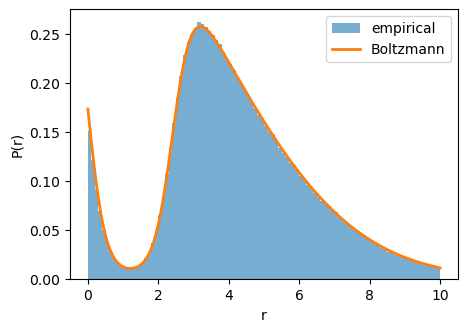

In [56]:
# --- Boltzmann sampling check -----------------------------
burn = int(0.2 * sim.ns)
r_traj = sim.r[burn:, 0, :]                          # shape (n, N)

# samples = r_traj[mask]
samples = r_traj[::100].flatten()

# Boltzmann on the left basin (renormalized over r < x_bar)
xs = np.linspace(1e-2, 10, 5000)
left_mask = xs < x_bar
# P_left = np.exp(-(U_vals - U_well) / T_bath)  * left_mask
# P_left /= np.trapz(P_left, xs)

# Boltzmann on the whole support
P_full = np.exp(-(U_vals - U_well) / T_bath)
P_full /= np.trapz(P_full, xs)

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.hist(samples, bins=100, density=True, range=(r_min, 10), alpha=0.6,
        label="empirical")
ax.plot(xs, P_full, lw=2, label="Boltzmann")
ax.set_xlabel("r"); ax.set_ylabel("P(r)"); ax.legend()

In [ ]:
out_dir = "media/figures/20260606"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "empirical_vs_boltzmann_for_arbitrary_potential_high_T.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260606/empirical_vs_boltzmann_for_arbitrary_potential_high_T.pdf


#### Recovering the Kramers exit rate

In [12]:
r_traj = sim.r[:, 0, :]
limit = x_bar
crossed = r_traj > limit
first_exit = np.where(crossed.any(0), crossed.argmax(0), sim.ns)
mask = np.arange(sim.ns)[burn:, None] < first_exit[None, :]

In [61]:
def scalar_reference(positions, a, b):
    positions = np.asarray(positions, dtype=float)
    if positions.ndim == 1:
        positions = positions[:, None]
    n, N = positions.shape
    A_intervals = [[] for _ in range(N)]
    B_intervals = [[] for _ in range(N)]
    in_A = positions[0] <= a
    in_B = positions[0] > a
    A_entry = np.zeros(N)
    B_entry = np.zeros(N)
    for i in range(1, n):
        r = positions[i]
        for k in range(N):
            if r[k] >= b and in_A[k]:
                B_entry[k] = i
                A_intervals[k].append(B_entry[k] - A_entry[k])
                in_A[k] = False
                in_B[k] = True
            if r[k] <= a and in_B[k]:
                A_entry[k] = i
                B_intervals[k].append(A_entry[k] - B_entry[k])
                in_B[k] = False
                in_A[k] = True
    return A_intervals, B_intervals

r_traj = sim.r[:, 0, :]

A_intervals_ref, B_intervals_ref = scalar_reference(r_traj, x_bar_a, x_bar_b)

In [62]:
first_exit_cum = []
first_entry_cum = []

for i in range(sim.N):
    # first_exit_cum = np.concatenate((first_exit_cum, sim.A_intervals[i][10:]))
    # first_entry_cum = np.concatenate((first_entry_cum, sim.B_intervals[i][10:]))

    first_exit_cum = np.concatenate((first_exit_cum, A_intervals_ref[i][1:]))
    first_entry_cum = np.concatenate((first_entry_cum, B_intervals_ref[i][1:]))

empirical rate  k = 1/<T_exit> = 0.3107
Kramers   rate  k             = 0.2672
ratio empirical / Kramers     = 1.16


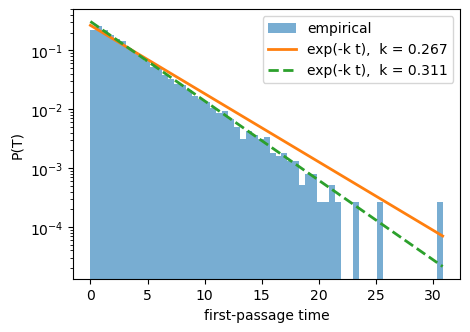

In [63]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] > limit).any(0)
# fpt = first_exit[exited] * sim.dt * sim.nskip
fpt = first_exit_cum * sim.dt * sim.nskip
# print(f"{exited.sum()}/{sim.N} trajectories exited")

tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kB*T_bath)/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - 0)/ (kB*T_bath))))

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 60)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_kramers:.3f}")
ax.plot(t_grid, k_emp * np.exp(-k_emp * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}", linestyle="dashed")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")

### Rouse potential + attractive well

#### Load data

In [322]:
import json, glob
import numpy as np

# _data_dir = "data/20260528/rouse_mfpt_attractive"
# _data_dir = "data/20260611/rouse_mfpt_attractive"
# _data_dir = "data/20260612/rouse_mfpt_attractive"
_data_dir = "data/20260615/rouse_mfpt_attractive"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _cpu_id = list(_raw.keys())[0]
    for _run_id, _run in _raw[_cpu_id].items():
        _alpha = _run["alpha"]
        data[_alpha] = _run

# --- sort alphas ---
alphas = np.array(sorted(data.keys()))
nparams = len(alphas)

# infer params from first entry
_first = data[alphas[0]]
params         = _first["rouse_params"]
nsteps_distance = int(params["nsteps"] / _first["sample_skip"])
# nsteps_full     = params["nsteps_full"]
dt              = params["dt"]

t_grid_distance = np.arange(nsteps_distance) * dt
# t_grid_full     = np.arange(nsteps_full) * dt
nsteps_pot     = len(_first["total_potential"])

# pre-allocate (sizes inferred from first entry)
# _nfpt = len(_first["contact_times"])
# _nicdf = len(_first["inverse_cdf"])
# _nhist = len(_first["hist_centers"])
# _nmsd  = len(_first["msd_bead1"])

distance_traj    = np.empty((nparams, nsteps_distance))
# contact_times    = [None] * nparams   # variable-length per alpha
# inverse_cdf      = [None] * nparams
# hist_centers     = np.empty((nparams, _nhist))
# hist_counts      = np.empty((nparams, _nhist))
# msd_bead1        = np.empty((nparams, _nmsd))
# msd_beadMid      = np.empty((nparams, _nmsd))
# msd_pairDistance = np.empty((nparams, _nmsd))
total_potential    = np.empty((nparams, nsteps_pot))
runtime_min      = np.empty(nparams)

for _ic, _alpha in enumerate(alphas):
    _r = data[_alpha]
    distance_traj[_ic]    = np.array(_r["distance_traj"])
    total_potential[_ic]  = np.array(_r["total_potential"])
    # contact_times[_ic]    = np.array(_r["contact_times"])
    # inverse_cdf[_ic]      = np.array(_r["inverse_cdf"])
    # hist_centers[_ic]     = np.array(_r["hist_centers"])
    # hist_counts[_ic]      = np.array(_r["hist_counts"])
    # msd_bead1[_ic]        = np.array(_r["msd_bead1"])
    # msd_beadMid[_ic]      = np.array(_r["msd_beadMid"])
    # msd_pairDistance[_ic] = np.array(_r["msd_pairDistance"])
    runtime_min[_ic]      = _r["runtime_min"]

In [348]:
from viz_util.bvp_solver import (
    Parameters, d2fb_dphi2, 
)

keya = 10
p_sim = data[alphas[keya]]["surface_params"]

p = Parameters(
    nb=p_sim["nb"],
    chi_b=p_sim["chi_b"],
    omega_b=p_sim["omega_b"],
    kappa=p_sim["kappa"],
    phi_inf=p_sim["phi_inf"],
    L=10.0,
    eps=1e-6,
    R=p_sim["R"],
    conserve_volume=False,
    parallel_plates=False
)

kuhnLength = data[alphas[keya]]["rouse_params"]["kuhn_length"]
beadSep = data[alphas[keya]]["rouse_params"]["bead_separation"]

barrier    : r=3.890,  U=-2.634,  ω_bar =0.959
ΔU = 5.988


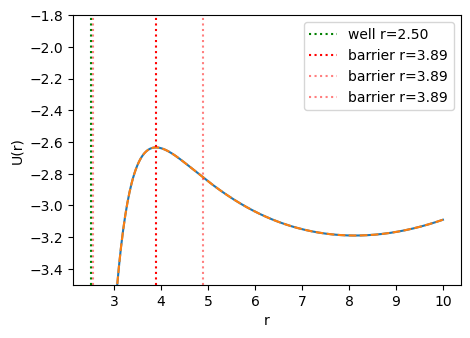

In [349]:
def U(r, *args):
    R, h0, kappa, lam, a, s = args

    # profile = np.where(r >= R, np.exp(-lam*(r-R))*R/r, 1)
    profile = np.exp(-lam*(r-R))*R/r

    return (
        - 2 * np.log(r) + 3*r**2/(2*s*a**2) 
        - 4*np.pi*R**2*h0**2*profile/(kappa*(lam+1/R))
    )

def F(r, *args):
    """Analytic force F = -dU/dx (only valid for x > 0)."""
    R, h0, kappa, lam, a, s = args

    # attrForce = np.where(r >= R, 1, 0)
    attrForce = 1

    return (
        2 / r - 3*r/(s*a**2) 
        - attrForce*4*np.pi*R**3*h0**2*np.exp(-lam*(r-R))*(lam/r+1/r**2)/(kappa*(lam+1/R))
    )

# --- locate left well, barrier; compute ΔU and curvatures ---
xs = np.linspace(p.R, p.L, 500)

lam = np.sqrt(d2fb_dphi2(p.phi_inf, p))
args = (p.R, p.omega_b, p.kappa, lam, kuhnLength, beadSep)
U_vals = U(xs, *args)
U_sim = data[alphas[keya]]["total_potential"]

# left = xs < 10
i_well = np.argmin(U_vals)
x_well, U_well = xs[i_well], U_vals[i_well]

# Barrier = first zero-crossing of dU/dx past the well.
# At a maximum the force F = -dU/dx flips from - to +; the first sign change
# of F (scanning outward from the well) marks the ridge between the two wells.
F_vals = F(xs, *args)
after_well = xs > x_well
sign_change = (np.sign(F_vals[after_well][:-1]) < 0) & (np.sign(F_vals[after_well][1:]) > 0)
i_cross = np.argmax(sign_change)  # first True; argmax stops at the first one
assert sign_change.any(), "no F-sign-change found past the well — barrier not located"

# linear interpolation between the bracketing samples for a sub-grid root
x_lo = xs[after_well][i_cross]
x_hi = xs[after_well][i_cross + 1]
F_lo, F_hi = F_vals[after_well][i_cross], F_vals[after_well][i_cross + 1]
x_bar = x_lo - F_lo * (x_hi - x_lo) / (F_hi - F_lo)
eps = 0.2
x_bar_a = p.R + 0.05
x_bar_b = x_bar+1
U_bar = U(x_bar, *args)

dU = U_bar - U_well

# numerical curvatures
def d2U(x):
    h = 1e-3
    return (U(x + h, *args) - 2 * U(x, *args) + U(x - h, *args)) / h**2

# omega_well = np.sqrt(d2U(x_well))  # >0
omega_bar = np.sqrt(-d2U(x_bar))  # |U''| at the saddle

# print(f"left well  : r={x_well:.3f}, U={U_well:.3f}, ω_well={omega_well:.3f}")
print(f"barrier    : r={x_bar:.3f},  U={U_bar:.3f},  ω_bar ={omega_bar:.3f}")
print(f"ΔU = {dU:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.plot(xs, U_vals)
ax.plot(xs, U_sim, linestyle="dashed")
ax.axvline(x_well, color="g", ls=":", label=f"well r={x_well:.2f}")
ax.axvline(x_bar, color="r", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_a, color="r", ls=":", label=f"barrier r={x_bar:.2f}", alpha=0.5)
ax.axvline(x_bar_b, color="r", ls=":", label=f"barrier r={x_bar:.2f}", alpha=0.5)
ax.set_xlabel("r")
ax.set_ylabel("U(r)")
ax.set_ylim(-3.5, -1.8)
ax.legend()

In [358]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_attr_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_attr_potential.pdf


#### Simulating Langevin

In [92]:
# --- parameter selection -------------------------------------------------
# 1) Temperature: ΔU/(kBT) in [3, 7] is the Arrhenius sweet spot --- escape
#    is rare enough to be exponentially distributed, frequent enough to
#    collect statistics in reasonable wall-clock time.
T_bath = 1.5                    # -> ΔU/T ≈ 4.6 here
gamma  = 1.0
kB     = 1.0
D = kB*T_bath/gamma

# 2) Time step: needs to satisfy BOTH
#       dt < (1/10) * γ / max|U''|         (drift stability)
#       √(2 kBT/γ * dt) << min feature size (noise step << well width)
dV_R = -F(p.R, *args)
relax_well = gamma*kB*T_bath / dV_R**2             # γ / U''(well)
relax_bar  = gamma / abs(d2U(x_bar))          # γ / |U''(barrier)|
dt_drift   = 0.05 * min(relax_well, relax_bar)
noise_step_target = 0.1 * (x_bar - x_well)    # << 1/10 of well-to-barrier distance
dt_noise   = noise_step_target ** 2 / (2 * kB * T_bath / gamma)
dt         = min(dt_drift, dt_noise)
print(f"dt_drift = {dt_drift:.4f}, dt_noise = {dt_noise:.4f}  ->  using dt = {dt:.4f}")

# 3) Total time: a few mean Kramers escape times so we observe many exits.
omega_bot = np.sqrt(d2U(8))
dU_bot = U(x_bar, *args) - U(8, *args)
tau_bot = (2 * np.pi * gamma / (omega_bot * omega_bar)) * np.exp(dU_bot / (kB * T_bath))

tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kB*T_bath)/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - p.R)/ (kB*T_bath))))
tau   = 500 * tau_K

print("delta_1^2: ", 1/omega_bot**2)
print(f"Kramers mean exit time from entropic well ≈ {tau_bot:.2f},  using tau = {tau:.1f}")

# 4) Reflecting wall well clear of the 1/r singularity, but where U(r_min) is
#    so high that the equilibrium weight there is negligible (~ exp(-U/T)).
r_min = p.R+0.01
print(f"U(r_min)/T = {U(r_min, *args)/T_bath:.1f}  (should be >> 1)")

# 5) Number of trajectories — limited by RAM: shape (n, dim, N).
N = 5000
nskip = 10
print(f"n_steps = {int(tau/dt)},  memory ≈ {int(tau/dt)*N*8/1e6/nskip:.0f} MB per array")

sim = lgv.OverdampedHarmonicLangevin(
    tau=tau, dim=1, N=N, dt=dt,
    T=T_bath, gamma=gamma, kB=kB,
    F=lambda r: F(r, *args),
    r0=p.R,
    r_min=r_min,
    seed=42,
    nskip=nskip,
    ab = (x_bar_a, x_bar_b)
)
sim.generate()

print("min(r) =", sim.r.min(), " (should be ≥ r_min)")

dt_drift = 0.0002, dt_noise = 0.0064  ->  using dt = 0.0002
delta_1^2:  16.251405127689324
Kramers mean exit time from entropic well ≈ 38.23,  using tau = 4582.9
U(r_min)/T = -5.6  (should be >> 1)
n_steps = 21852322,  memory ≈ 87409 MB per array


MemoryError: Unable to allocate 81.4 GiB for an array with shape (2185233, 1, 5000) and data type float64

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


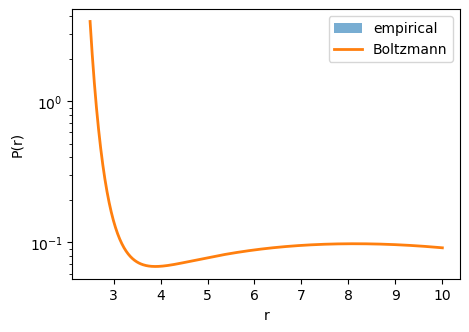

In [91]:
# --- Boltzmann sampling check -----------------------------
burn = int(0.2 * sim.ns)
r_traj = sim.r[burn:, 0, :]                          # shape (n, N)
samples = r_traj.flatten()

# Boltzmann on the whole support
P_full = np.exp(-(U_vals - U_well) / (kB*T_bath))
P_full /= np.trapz(P_full, xs)

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.hist(samples, bins=100, density=True, range=(r_min, p.L), alpha=0.6,
        label="empirical")
ax.plot(xs, P_full, lw=2, label="Boltzmann")
ax.set_yscale('log')
ax.set_xlabel("r"); ax.set_ylabel("P(r)"); ax.legend()

In [109]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_boltzmann_langevin.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_boltzmann_langevin.pdf


#### Kramers exit rate (Langevin)

In [ ]:
# r_traj = sim.r[:, 0, :]
# limit = x_bar
# crossed = r_traj > limit
# first_exit = np.where(crossed.any(0), crossed.argmax(0), len(r_traj))
# mask = np.arange(len(r_traj))[burn:, None] < first_exit[None, :]

In [89]:
first_exit_cum = []
first_entry_cum = []

for i in range(sim.N):
    first_exit_cum = np.concatenate((first_exit_cum, sim.A_intervals[i][1:]))
    first_entry_cum = np.concatenate((first_entry_cum, sim.B_intervals[i][1:]))

empirical rate  k = 1/<T_exit> = nan
Kramers   rate  k             = 0.1091
ratio empirical / Kramers     = nan


/tmp/ipykernel_257284/1303255116.py:9: RuntimeWarning: Mean of empty slice.
  mean_fpt = fpt.mean()
/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: zero-size array to reduction operation maximum which has no identity

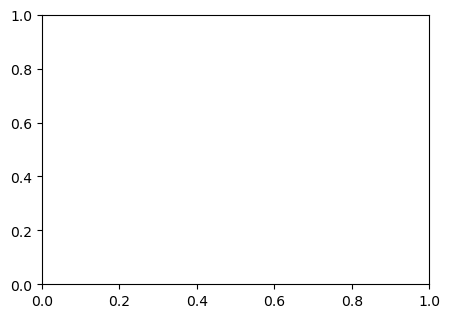

In [90]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] < limit).any(0)
# fpt = first_exit[exited] * sim.dt * sim.nskip
fpt = first_exit_cum * sim.dt
# print(f"{exited.sum()}/{sim.N} trajectories exited")

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 1.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")
# ax.set_xscale("log")

In [115]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_exit_rate_langevin.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_exit_rate_langevin.pdf


#### Distance trace

nsteps:  100000
total physical time:  50.0
bead relaxation time:  0.3333333333333333


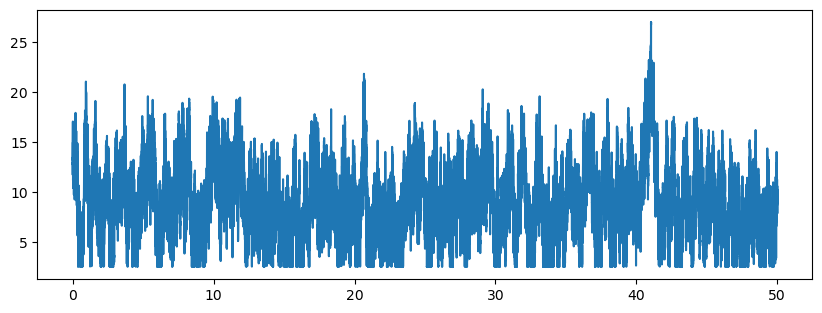

In [11]:
fig, ax = plt.subplots(1,1,figsize=(10, 3.5))

ax.plot(t_grid_distance, distance_traj[1])
print("nsteps: ", nsteps_distance)
print("total physical time: ", dt*nsteps_distance)
print("bead relaxation time: ", _first["bead_relax_time"])
# ax.set_xlim(10, 200)

#### Distance hist

0.15


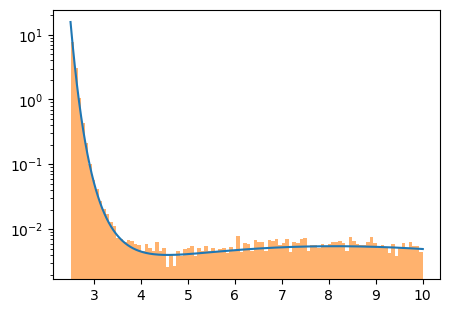

In [358]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))

keya = 15
b = _first["rouse_params"]["kuhn_length"]
R = _first["surface_params"]["R"]
kBT = _first["rouse_params"]["kBT"]
subsampled = distance_traj[keya]

N = _first["rouse_params"]["N"]
# dist = xs**2 * np.exp(-3*xs**2/(2*N*b**2))
# dist = dist / np.sum(dist)

pot = total_potential[keya]
xs2 = np.linspace(p.R, p.L, len(pot))
P_eq = np.exp(-pot/kBT)
P_eq /= np.trapz(P_eq, xs2)

ax.plot(xs, P_eq)
_=ax.hist(subsampled, density=True, bins=100, range=(p.R, p.L), alpha=0.6)
# ax.axvline(np.sqrt(N)*b)
ax.set_yscale('log')
print(alphas[keya])


In [355]:
_first["surface_params"]

{'chi_b': 2.5,
 'omega_b': -0.5,
 'kappa': 1.0,
 'phi_inf': 0.003,
 'R': 2.5,
 'nb': 1.0}

In [46]:
out_dir = "media/figures/20260615"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_distance_distribution_match_boltzmann.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260615/rouse_distance_distribution_match_boltzmann.pdf


#### Kramers exit rate (Rouse)

In [18]:
dt = data[alphas[keya]]["rouse_params"]["dt"]
nskip = data[alphas[keya]]["sample_skip"]
kBT = data[alphas[keya]]["rouse_params"]["kBT"]
gamma = data[alphas[keya]]["rouse_params"]["friction"]

T_bath = kBT

dV_R = -F(p.R, *args)
tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kBT)/omega_bar) 
         * np.exp(dU / (kBT)) * (1 - np.exp(-dV_R * (x_bar - p.R)/ (kBT))))
tau   = 500 * tau_K

In [19]:
r_traj = distance_traj[::1]

a = p.R + 0.05
b = x_bar
a_crossings = []
b_crossings = []
ab_intervals = []
ba_intervals = []
in_a = False
in_b = False
entered_a, entered_b, exited_a, exited_b = None, None, None, None

for i, xi in enumerate(r_traj):
    if xi < a and not in_a:
        in_a = True
        entered_a = i
        if exited_b is not None:
            ab_intervals.append(entered_a - exited_b)

    if xi > a and r_traj[i-1] <= a:
        in_a = False
        exited_a = i

    if xi > b and not in_b:
        in_b = True
        entered_b = i
        if exited_a is not None:
            ba_intervals.append(entered_b - exited_a)

    if xi < b and r_traj[i-1] >= b:
        in_b = False
        exited_b = i

first_exit = np.array(ab_intervals)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [20]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] > limit).any(0)
exited = (subsampled > limit).any(0)

fpt = first_exit * dt * nskip * 10
print(f"{exited.sum()}/{1} trajectories exited")

D = (kBT) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")

NameError: name 'limit' is not defined

### Mean-squared displacement

Text(0.5, 1.0, 'single locus')

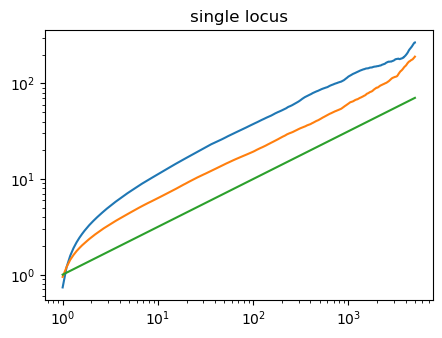

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))
maxlag = dt*len(msd_bead1[0])
msd_time = np.linspace(1, maxlag, len(msd_bead1[0]))
_=ax.plot(msd_time, msd_bead1[0])
_=ax.plot(msd_time, msd_beadMid[0])
ax.plot(msd_time, msd_time**0.5)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title("single locus")

Text(0.5, 1.0, 'two locus')

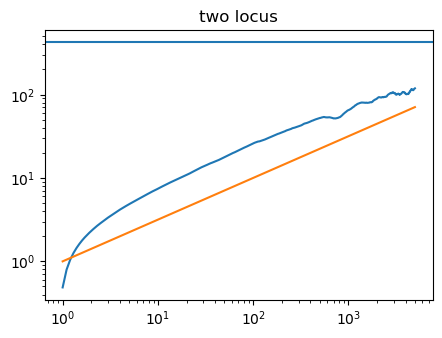

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))
maxlag = dt*len(msd_bead1[0])
msd_time = np.linspace(1, maxlag, len(msd_bead1[0]))
_=ax.plot(msd_time, msd_pairDistance[0])
ax.plot(msd_time, msd_time**0.5)
ax.axhline(y=np.mean(distance_traj**2))
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title("two locus")

### Quick look at Fisher rates

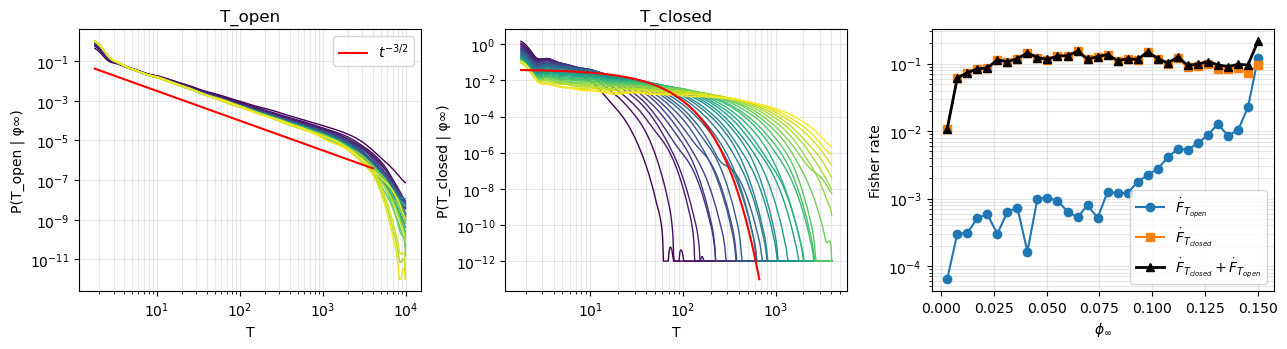

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

PATH = "media/figures/20260528/rouse_mfpt_attractive_fisher_hires.json"

with open(PATH) as f:
    blob = json.load(f)

# scalars / arrays indexed by phi_inf
phi_inf    = np.asarray(blob["phi_inf"], dtype=float)
d_ridge    = np.asarray(blob["d_ridge"], dtype=float)
joint_rate = np.asarray(blob["joint_rate"], dtype=float)

# helper: JSON-encoded arrays may contain `None` where the analysis produced
# a NaN (empty histogram bin, log of 0, etc.). Cast back to NaN for math.
def arr(x):
    return np.asarray(x, dtype=float)   # None -> NaN automatically

def unpack(group):
    return dict(
        T_grid           = arr(group["T_grid"]),            # (n_T,)
        pdfs             = arr(group["pdfs"]),              # (n_phi, n_T)
        mean_T           = arr(group["mean_T"]),            # (n_phi,)
        fisher_per_event = arr(group["fisher_per_event"]),  # (n_phi,) wrt log phi
        fisher_rate      = arr(group["fisher_rate"]),       # (n_phi,) per unit time
    )

open_  = unpack(blob["open"])
closed = unpack(blob["closed"])

# ---- quick sanity plots --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
cmap = plt.get_cmap("viridis")

for name, g in [("T_open", open_), ("T_closed", closed)]:
    ax = axes[0] if name == "T_open" else axes[1]
    for i in range(len(phi_inf)):
        if not np.all(np.isnan(g["pdfs"][i])):
            ax.loglog(g["T_grid"], np.clip(g["pdfs"][i], 1e-12, None),
                      color=cmap(i / max(1, len(phi_inf) - 1)), lw=1.0)
    ax.set_xlabel("T"); ax.set_ylabel(f"P({name} | φ∞)")
    ax.set_title(name); ax.grid(True, which="both", alpha=0.3)

lam = 0.04
stop=int(len(g["T_grid"]) / 1.3)
axes[0].plot(g["T_grid"], g["T_grid"]**(-3/2)*0.1, color="red", label=r"$t^{-3/2}$")
axes[0].legend()
axes[1].plot(g["T_grid"][:stop], lam*np.exp(-g["T_grid"][:stop]*lam), color="red")

ax = axes[2]
ax.plot(phi_inf, open_["fisher_rate"],   "o-", label=r"$\dot F_{T_{open}}$")
ax.plot(phi_inf, closed["fisher_rate"],  "s-", label=r"$\dot F_{T_{closed}}$")
ax.plot(phi_inf, joint_rate,             "^-", color="k", lw=2, label=r"$\dot F_{T_{closed}}+\dot F_{T_{open}}$")
ax.set_xlabel(r"$\phi_\infty$"); ax.set_ylabel("Fisher rate")
ax.set_yscale("log"); ax.legend(); ax.grid(True, which="both", alpha=0.3)

plt.tight_layout(); plt.show()

In [ ]:
out_dir = "media/figures/20260528"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fpt_pdfs_open_close_fisher_rates.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260528/fpt_pdfs_open_close_fisher_rates.pdf


### Fisher rate, Langevin dynamics

#### Load Langevin data

In [22]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "data/20260627/langevin_open_close_exit_at_bar"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _keyas = list(_raw.keys())
    for _keya in _keyas:
        for _run_id, _run in _raw[_keya]["1"].items():
            keya = _run["keya"]
            data[keya] = _run

#### Checking equilibration

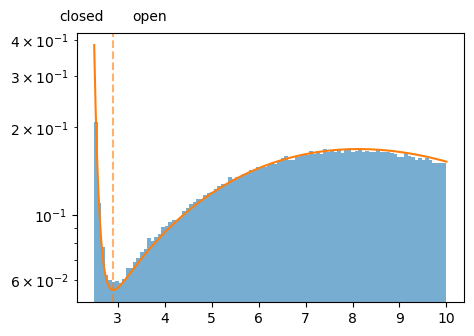

In [25]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))

keya = 3

U_vals      = np.array(data[keya]["total_potential"])
xs          = np.array(data[keya]["pot_grid"])
T_bath      = data[keya]["langevin_params"]["T_bath"]
kB          = data[keya]["langevin_params"]["kB"]
kBT         = kB*T_bath
x_bar       = data[keya]["x_bar"]

P_full = np.exp(-(U_vals) / (kBT))
P_full /= np.trapz(P_full, xs)

bot = np.min(P_full)
height = np.max(P_full)/np.min(P_full)

ax.hist(data[keya]["distance_traj"], density=True, bins=100, 
          range=(xs[0], xs[-1]), alpha=0.6)
ax.plot(xs, P_full)
ax.axvline(x=x_bar, linestyle="dashed", color="C1", alpha=0.6)
ax.text(x_bar-1.14, bot*height**1.1, "closed")
ax.text(x_bar+0.4, bot*height**1.1, "open")
ax.set_yscale("log")

In [26]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "langevin_P_eq_ok_lowc.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/langevin_P_eq_ok_lowc.pdf


#### Checking entry/exit time histograms

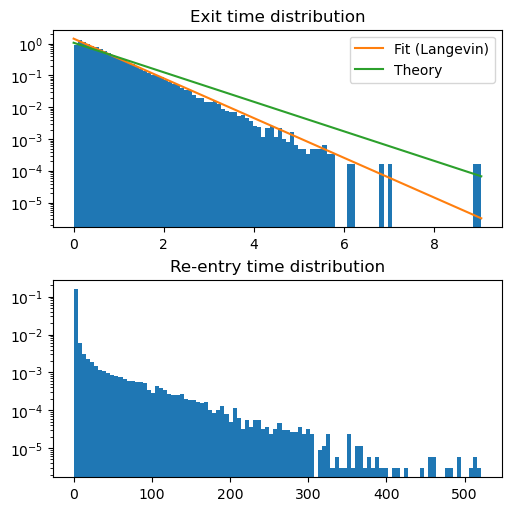

In [42]:
keya = 10

exit_times = data[keya]["exit_times"]
reentry_times = data[keya]["reentry_times"]
k_exit = data[keya]["k_exit"]
k_kramers = 2*data[keya]["k_kramers"]
k_reentry = data[keya]["k_reentry"]

fig, ax = plt.subplots(2,1,figsize=(5, 5), layout="constrained")

exit_grid = np.linspace(0, np.max(exit_times), 100)
ax[0].hist(exit_times, bins=100, density=True)
ax[0].set_yscale('log')
ax[0].plot(exit_grid, k_exit*np.exp(-k_exit*exit_grid), 
           label="Fit (Langevin)")
ax[0].plot(exit_grid, k_kramers*np.exp(-k_kramers*exit_grid),
           label="Theory")
ax[0].set_title("Exit time distribution")
ax[0].legend()

ax[1].set_title("Re-entry time distribution")
entry_grid = np.linspace(0, 300, 100)
ax[1].hist(reentry_times, bins=100, density=True)
ax[1].set_yscale('log')
# ax[1].set_xscale('log')
# ax[1].plot(entry_grid, k_reentry*np.exp(-k_reentry*entry_grid))

In [43]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "exit_reentry_dists.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/exit_reentry_dists.pdf


#### Exit rate and re-entry time

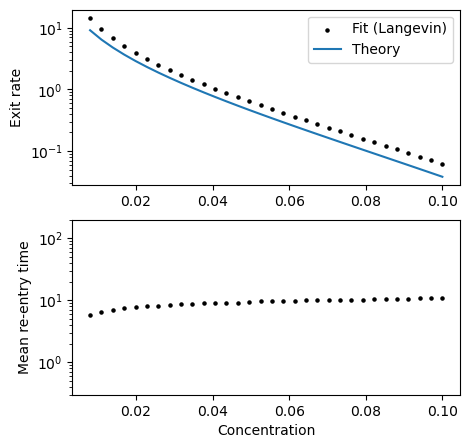

In [48]:
keyas = np.sort(list(data.keys()))

concentrations = np.array([data[keya]["alpha"] for keya in keyas])
k_exit_vals =  np.array([data[keya]["k_exit"] for keya in keyas])
k_kramers_vals =  np.array([data[keya]["k_kramers"] for keya in keyas])
mean_exit_time_vals =  1/k_exit_vals
mean_reentry_time_vals =  np.array([data[keya]["mean_reentry_time"] for keya in keyas])
mean_cycle_time_vals = mean_exit_time_vals + mean_reentry_time_vals

fig, ax = plt.subplots(2,1,figsize=(5, 5))

ax[0].scatter(concentrations, k_exit_vals, s=20, marker=".",c="black", label="Fit (Langevin)")
ax[0].plot(concentrations, 2*k_kramers_vals, label="Theory")
ax[0].set_ylabel("Exit rate")
ax[0].set_yscale("log")
ax[0].legend()

ax[1].scatter(concentrations, mean_reentry_time_vals, s=20, marker=".",c="black")
ax[1].set_ylabel("Mean re-entry time")
ax[1].set_xlabel("Concentration")
ax[1].set_ylim(0.3, 200)
ax[1].set_yscale('log')

In [45]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rates_vs_c.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/rates_vs_c.pdf


#### Local concentration and transcription dynamics

In [3]:
phi_local_vals = np.zeros(len(keyas))
p_closed_vals = np.zeros(len(keyas))

def U(r, *args):
    R, h0, kappa, lam, a, s = args
    profile = np.exp(-lam * (r - R)) * R / r

    return (
        - 2 * np.log(r) + 3 * r ** 2 / (2 * s * a ** 2)
        - 4 * np.pi * R ** 2 * h0 ** 2 * profile / (kappa * (lam + 1 / R))
    )

for k, keya in enumerate(keyas):

    # U_vals      = np.array(data[keya]["total_potential"])
    # xs          = np.array(data[keya]["pot_grid"])
    T_bath      = data[keya]["langevin_params"]["T_bath"]
    kB          = data[keya]["langevin_params"]["kB"]
    kBT         = kB*T_bath
    x_bar       = data[keya]["x_bar"]
    lam         = data[keya]["lam"]
    R           = data[keya]["R"]
    L           = data[keya]["surface_params"]["L"]
    kuhnLength  = data[keya]["rouse_params"]["kuhn_length"]
    beadSep     = data[keya]["rouse_params"]["bead_separation"]
    kappa       = data[keya]["surface_params"]["kappa"]
    omega_b     = data[keya]["surface_params"]["omega_b"]
    phi_inf     = data[keya]["alpha"]
    
    args = (R, omega_b, kappa, lam, kuhnLength, beadSep)
    xs = np.linspace(R, L, 100000)
    U_vals = U(xs, *args)

    P_full = np.exp(-(U_vals) / (kBT))
    P_full /= np.trapz(P_full, xs)

    i_closed = np.where(xs < x_bar)[0]
    p_closed = np.trapz(P_full[i_closed], xs[i_closed])
    p_closed_vals[k] = p_closed

    profile = (phi_inf - omega_b * (np.exp(-lam * (xs - R)) * R / xs) 
                / (kappa * (lam + 1 / R)))
    phi_local_vals[k] = np.trapz(P_full[i_closed]*profile[i_closed]/p_closed, 
                        xs[i_closed])
    
# steady-state transcription model
kb = 1.0
ku = 1.0
tau_on_vals = 1 / (phi_local_vals*kb + k_exit_vals)
tau_off_vals = 1 / (ku + k_exit_vals)
tau_closed_vals = tau_on_vals + tau_off_vals
p_on_vals = p_closed_vals * tau_on_vals / tau_closed_vals
p_off_vals = p_closed_vals * tau_off_vals / tau_closed_vals

p_off_to_open_vals = k_exit_vals / (k_exit_vals + phi_local_vals*kb)
p_on_to_open_vals = k_exit_vals / (k_exit_vals + ku)

fig, ax = plt.subplots(2,1, figsize=(5, 5))

ax[0].plot(concentrations, phi_local_vals)
ax[0].plot(concentrations, concentrations, linestyle="dashed", 
        color="black", alpha=0.6)
ax[0].set_ylabel("Local concentration")
ax[0].set_ylabel("Concentration")

ax[1].plot(concentrations, p_closed_vals)
ax[1].plot(concentrations, mean_exit_time_vals / mean_cycle_time_vals)

NameError: name 'keyas' is not defined

#### Log derivatives and Fisher rate

Text(0.5, 0, 'Concentration')

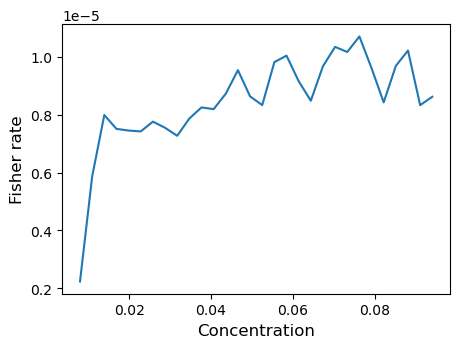

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

# exit rate
k_vals = k_exit_vals
d_exit_vals = np.gradient(k_vals)
d2_exit_vals = np.gradient(np.gradient(k_vals))
d2_log_exit_vals = d2_exit_vals/k_vals - (d_exit_vals/k_vals)**2

# local concentration
d_phi_local_vals = np.gradient(phi_local_vals)
d2_phi_local_vals = np.gradient(np.gradient(phi_local_vals))
d2_log_phi_local_vals = (d2_phi_local_vals/phi_local_vals 
                         - (d_phi_local_vals/phi_local_vals)**2)

# shorthands
c = concentrations
p4 = p_off_vals
p41 = p_off_to_open_vals
p3 = p_on_vals
p31 = p_on_to_open_vals

# fisher rate
fisher_rate_vals = (
    c**2*(d2_exit_vals*p_closed_vals + d2_phi_local_vals*p_off_vals
          -((p4*p41 + p3+p31)*d2_log_exit_vals
            + p4*p41*d2_log_phi_local_vals)/mean_cycle_time_vals)
)

ax.plot(concentrations[:-2], fisher_rate_vals[:-2])
ax.set_ylabel("Fisher rate", fontsize=12)
ax.set_xlabel("Concentration", fontsize=12)

### Fisher rate, Rouse dynamics

#### Take a look at the potentials

In [4]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "/home/tohme/.julia/dev/Droplet/media/figures/"
_data_dir += "20260628/fisher_two_spheres_chi_2.5_h0_-0.5_R_5.0_sweep_c.json"

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
with open(_data_dir, 'r') as _f:
    data = json.load(_f)

U_grids = np.array(data["groups"][0]["U_full_grid"])
d_grid = np.array(data["groups"][0]["d_grid"])

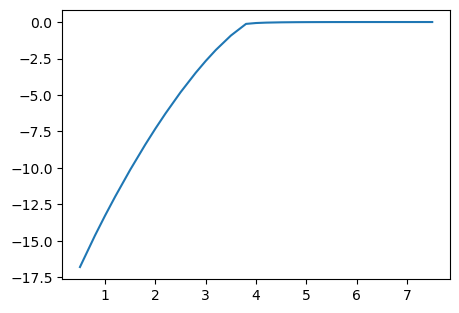

In [5]:
from scipy.interpolate import make_interp_spline

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

key = 30
U_interp = make_interp_spline(
    d_grid[1:], 
    U_grids[key][1:],
    k=5
)

xs = np.linspace(d_grid[0], d_grid[-1], 500)
ax.plot(d_grid, U_grids[key])
# ax.plot(xs, -U_interp(xs), linestyle="dashed")
# ax.set_yscale("log")

#### Load Rouse data

In [319]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "data/20260629/rouse_mfpt_attractive_nonlinear_test"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _keyas = list(_raw.keys())
    for _keya in _keyas:
        for _run_id, _run in _raw[_keya].items():
            data[int(_keya)-1] = _run

keya = 3
r_traj = np.array(data[keya]['distance_traj'])
U_total = np.array(data[keya]['total_potential'])
U_ads = np.array(data[keya]['ads_potential'])
kBT = data[keya]['rouse_params']["kBT"]
R = data[keya]['surface_params']["R"]
L = data[keya]['surface_params']["L"]

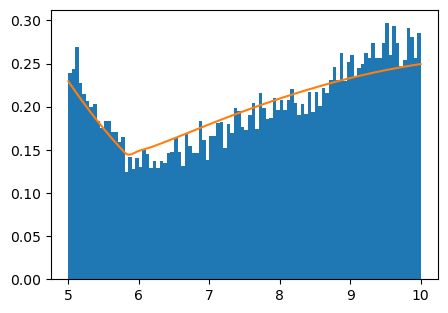

In [320]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

xs = np.linspace(R, L, len(U_total))
P_full = np.exp(-U_total / kBT)
P_full /= np.trapz(P_full, xs)

ax.hist(r_traj, bins=100, density=True, range=(5, 10))
ax.plot(xs, P_full)

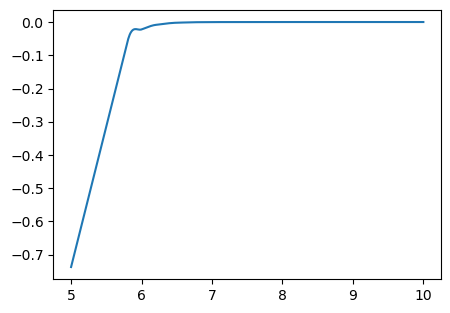

In [321]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))

ax.plot(xs, U_ads)
# ax.plot(d_grid[1:]+R, U_grids[0][1:])


### Two sphere BVP solution

In [563]:
import glob, json, os
import numpy as np

# DATA_DIR = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5"   # <-- point at your sweep's outdir
# DATA_DIR = "data/20260721/test"
# DATA_DIR = "data/20260722/fisher_two_spheres_R_4_h0_-0.5_chi_3"
# DATA_DIR = "data/20260722/fisher_two_spheres_chi_3_h0_-0.5_R_4"
# DATA_DIR = "data/20260724/R_4_h0_-1.0_chi_3/"
# DATA_DIR = "data/20260724/R_4_h0_-1.6_chi_4/"
# DATA_DIR = "data/20260724/R_4_h0_-0.6_chi_2.5/"
# DATA_DIR = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/"
DATA_DIR = "data/20260724/R_5_h0_-0.6_chi_2.5/"
# DATA_DIR = "data/20260725/R_5_h0_-0.6_chi_2.5/"

def load_fisher(data_dir):
    """Aggregate output_cpu*.json from a fisher_two_spheres sweep into a flat record list."""
    recs = []
    def descend(node):                        # sweep.jl nests as {keya: {keyb: record}}
        if isinstance(node, dict):
            if "phi_inf" in node and "U_full" in node:
                recs.append(node)
            else:
                for v in node.values(): descend(v)
        elif isinstance(node, list):
            for v in node: descend(v)
    files = sorted(glob.glob(os.path.join(data_dir, "output_cpu*.json")))
    assert files, f"no output_cpu*.json under {data_dir}"
    for f in files:
        with open(f) as fh: descend(json.load(fh))
    recs.sort(key=lambda r: (r["omega_b"], r["phi_inf"]))   # phi_inf ascending per omega_b
    return recs

records = load_fisher(DATA_DIR)
print(f"{len(records)} records | params sections:", list(records[0].get("params", {})))

64 records | params sections: ['sim', 'fpt', 'bvp', 'surface', 'sweep', 'rouse']


#### Quick look at the potentials

0.14479410825606476


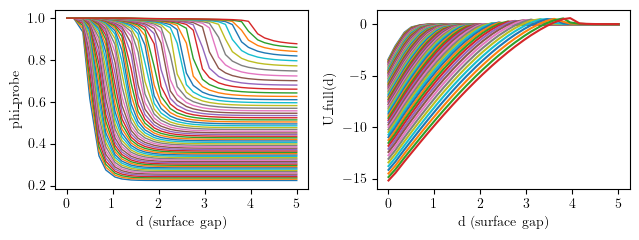

array([0.02895882, 0.03056765, 0.03217647, 0.03378529, 0.03539412,
       0.03700294, 0.03861176, 0.04022059, 0.04182941, 0.04343823,
       0.04504706, 0.04665588, 0.0482647 , 0.04987353, 0.05148235])

In [564]:
import matplotlib.pyplot as plt
arr = lambda x: np.array(x, dtype=float)      # Julia NaN/null -> np.nan

phi_inf = arr([r["phi_inf"] for r in records])
phi_surf   = arr([r["phi_surf"]   for r in records])
omega_b   = arr([r["omega_b"]   for r in records])
print(records[0]["binodal"])

fig, ax = plt.subplots(1, 2, figsize=(6.5, 2.5))

j, k = 0, 15
r = records[k]                          # equilibrium pair potential U_full(d)
for r in records:
    ax[0].plot(arr(r["d_grid"]), r["phi_surf"], lw=1)
ax[0].set(xlabel="d (surface gap)", ylabel="phi_probe");
# ax[0].set_ylim(0.35, 1.1)

for r in records:   
    ax[1].plot(arr(r["d_grid"]), arr(r["U_full"]), ms=3)

ax[1].set(xlabel="d (surface gap)", ylabel="U_full(d)"); 
# ax[1].set_xlim(-0.1, 2)
plt.tight_layout(); plt.show()
phi_inf[j:k]

### Interpolated potentials

In [601]:
import json
import numpy as np

# Same location as PARAMS.sim.output_dir / PARAMS.sim.interp_file
# INTERP_JSON = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260721/test/bvp_potential_interp.json"
# INTERP_JSON = "data/20260722/fisher_two_spheres_chi_3_h0_-0.5_R_4/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-1.0_chi_3/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-0.6_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_5_h0_-0.5_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260725/R_5_h0_-0.6_chi_2.5/bvp_potential_interp.json"
INTERP_JSON = "data/20260725/bvp_potential_interp.json"

def load_bvp_interp(path=INTERP_JSON):
    """bvp_potential_interp.jl output -> dict of numpy arrays (JSON null -> np.nan)."""
    with open(path) as f:
        d = json.load(f)
    arr = lambda x: np.array(x, dtype=float)
    return {
        "params":           d["params"],                 # full PARAMS tree (incl. sim, fpt, ...)
        "phi_inf":          arr(d["phi_inf"]),            # (nphi,)  == phi_inf_grid(PARAMS)
        "omega_b":          float(d["omega_b"]),
        "R":                float(d["R"]),
        "d_grid":           arr(d["d_grid"]),             # (N_D,)   BVP surface gaps
        "x_grid":           arr(d["x_grid"]),             # (Ngrid,) x = d + R
        "U_full_raw":       arr(d["U_full_raw"]),         # (nphi, N_D)   NaN where BVP unsolved
        "phi_surf_raw":     arr(d["phi_surf_raw"]),       # (nphi, N_D)   gap-facing surface phi
        "U_full_interp":    arr(d["U_full_interp"]),      # (nphi, Ngrid) nonlinear BVP, interpolated
        "phi_surf_interp":  arr(d["phi_surf_interp"]),      # (nphi, Ngrid) nonlinear BVP, interpolated
        "U_linear":         arr(d["U_linear"]),           # (nphi, Ngrid) linear-response U_ads
        "U_tot_full":       arr(d["U_tot_full"]),         # (nphi, Ngrid) + jacobian + Rouse spring
        "U_tot_linear":     arr(d["U_tot_linear"]),       # (nphi, Ngrid) + jacobian + Rouse spring
        "input_by_cpu":     d["input_by_cpu"],            # {cpu: {phi_inf, U_full, phi_surf, d_grid}}
    }

D = load_bvp_interp()
print({k: (v.shape if isinstance(v, np.ndarray) else type(v).__name__) for k, v in D.items()})
# e.g. index a phi_inf row:  x, U = D["x_grid"], D["U_tot_full"][0]


{'params': 'dict', 'phi_inf': (64,), 'omega_b': 'float', 'R': 'float', 'd_grid': (0,), 'x_grid': (1500,), 'U_full_raw': (64, 0), 'phi_surf_raw': (64, 0), 'U_full_interp': (64, 1500), 'phi_surf_interp': (64, 1500), 'U_linear': (64, 1500), 'U_tot_full': (64, 1500), 'U_tot_linear': (64, 1500), 'input_by_cpu': 'dict'}


0.1303146974304583

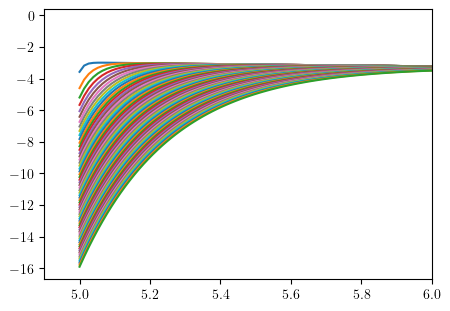

In [602]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

keya = 63
xend = -1
d_grid = D["x_grid"][:xend]
U_full_interp = D["U_full_interp"].T[:xend, :keya]
U_tot_linear = D["U_tot_linear"].T[:xend, :keya]
F_tot_full = - np.gradient(U_full_interp, d_grid, axis=0)
# _=ax.plot(d_grid, F_tot_full)
_=ax.plot(D["x_grid"][:xend], D["U_tot_linear"].T[:xend, :keya])
F_tot_linear = - np.gradient(U_tot_linear, d_grid, axis=0)
# ax.plot(d_grid, F_tot_linear)
# ax.set_ylim(-13.2, -2)
ax.set_xlim(4.9, 6)
phi_inf[keya]

### Exact FPT PDFs from solver

In [603]:
import json
import numpy as np

# dirname = "data/20260706/fpt_solver_c_sweep_h0_-0.3/fpt_solver_c_sweep.json"
# dirname = "data/20260718/fpt_solver_c_sweep_bvp/fpt_solver_c_sweep.json"
# dirname = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260722/fisher_two_spheres_R_5_h0_-0.6/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260721/test/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_4_h0_-0.6_chi_2.5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_5_h0_-0.5_chi_2.5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260725/R_5_h0_-0.6_chi_2.5/fisher_rate_from_fpt_solver.json"
dirname = "data/20260725/fisher_rate_from_fpt_solver.json"

with open(dirname) as f:
    d = json.load(f)

phi_infs = np.array(d["phi_infs"])            # swept concentrations (50,)
recs     = d["per_phi"]                        # list of 50 per-concentration records

# stack scalars into arrays indexed by phi
lam               = np.array([r["lam"]         for r in recs])
x_ridge           = np.array([r["x_ridge"]     for r in recs])
barrier           = np.array([r["barrier"]     for r in recs])
well_depth        = np.array([r["well_depth"]  for r in recs])
mfpt_esc          = np.array([r["escape_mfpt"] for r in recs])
mfpt_ret          = np.array([r["return_mfpt"] for r in recs])
fisher_rate       = np.array([r["fisher_rate"] for r in recs])
phi_surf_vals     = np.array([r["phi_surf"]    for r in recs])
phi_local_vals    = np.array([r["phi_local"]   for r in recs])
dphi_local_vals   = np.array([r["dphi_local"]  for r in recs])
dphi_surf_vals    = np.gradient(phi_surf_vals[:,0], phi_infs[:-2])

# per-phi curves are ragged only in name; grab one record like this:
r = recs[0]                                    # r["phi_inf"] == phi_infs[0]
x_esc, U_esc = np.array(r["x_grid_esc"]), np.array(r["U_tot_esc"])   # potential (escape grid)
x_ret, U_ret = np.array(r["x_grid_ret"]), np.array(r["U_tot_ret"])   # potential (return grid)
t_esc, pdf_esc = np.array(r["escape_t"]), np.array(r["escape_pdf"])  # escape FPT density
t_ret, pdf_ret = np.array(r["return_t"]), np.array(r["return_pdf"])  # return FPT density


#### Computed FPT distributions

/tmp/ipykernel_407755/1145541792.py:9: RuntimeWarning: invalid value encountered in log
  ax[0].plot(t_esc, np.log(pdf_esc), color="blue", alpha=0.5)
/tmp/ipykernel_407755/1145541792.py:13: RuntimeWarning: invalid value encountered in log
  ax[1].plot(t_ret, np.log(pdf_ret), color="blue", alpha=0.5)


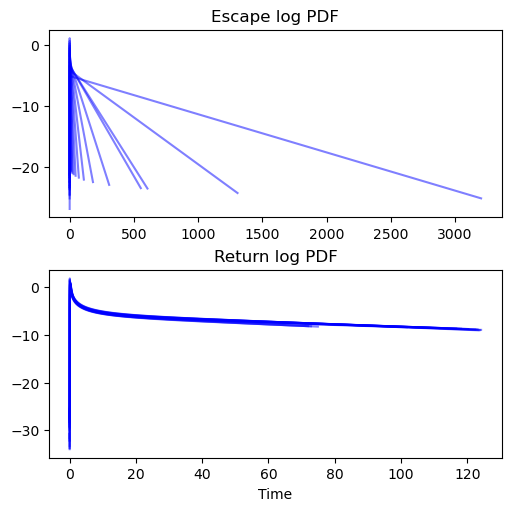

In [415]:
fig, ax = plt.subplots(2,1,figsize=(5, 5), layout="constrained")

for r in recs[:]:                                    # r["phi_inf"] == phi_infs[0]
    x_esc, U_esc = np.array(r["x_grid_esc"]), np.array(r["U_tot_esc"])   # potential (escape grid)
    x_ret, U_ret = np.array(r["x_grid_ret"]), np.array(r["U_tot_ret"])   # potential (return grid)
    t_esc, pdf_esc = np.array(r["escape_t"]), np.array(r["escape_pdf"])  # escape FPT density
    t_ret, pdf_ret = np.array(r["return_t"]), np.array(r["return_pdf"])  # return FPT density

    ax[0].plot(t_esc, np.log(pdf_esc), color="blue", alpha=0.5)
    ax[0].set_title("Escape log PDF")
    # ax[0].set_xscale("log")

    ax[1].plot(t_ret, np.log(pdf_ret), color="blue", alpha=0.5)
    ax[1].set_title("Return log PDF")
    ax[1].set_xlabel("Time")
    # ax[1].set_xscale("log")
    # ax[1].set_ylim(-6, 0)
    # ax[1].set_xlim(0, 50)

#### Diagnostics

Text(0.5, 0, 'Volume fraction')

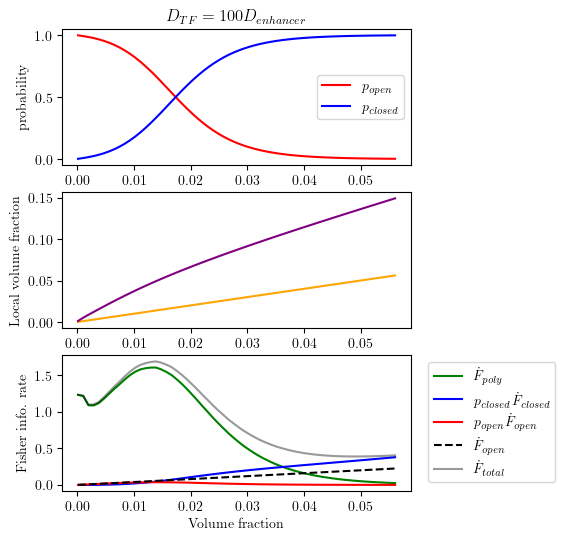

In [604]:
fig, ax = plt.subplots(3,1,figsize=(4.5, 6))

p_closed = mfpt_esc / (mfpt_esc + mfpt_ret)
p_open = mfpt_ret / (mfpt_esc + mfpt_ret)

a = 1        # um
D_tf = 1      # um^2/s
kb = 4*a*D_tf 
ku = 1e4
tau_closed = 1 / (kb*phi_local_vals) + 1 / ku
tau_open = 1 / (kb*phi_surf_vals[:,0]) + 1 / ku
phi_local_gain = (dphi_local_vals * phi_infs[0:-2] / phi_local_vals) ** 2
phi_surf_gain = (dphi_surf_vals * phi_infs[0:-2] / phi_surf_vals[:,0]) ** 2

fisher_rate_closed = phi_local_gain / tau_closed
fisher_rate_open = phi_surf_gain / tau_open

K = 1
fisher_rate_total = (
    fisher_rate*K + p_closed*fisher_rate_closed + p_open*fisher_rate_open
)

ax[0].plot(phi_infs[:-2], p_open, label=r"$p_{open}$", color="red")
ax[0].plot(phi_infs[:-2], p_closed, label=r"$p_{closed}$", color="blue")
ax[0].legend()
ax[0].set_title(r"$D_{TF} = 100D_{enhancer}$")
ax[0].set_ylabel("probability")

ax[1].plot(phi_infs[:-2], phi_surf_vals[:,0], color="orange")
ax[1].plot(phi_infs[:-2], phi_local_vals, color="purple")
ax[1].set_ylabel("Local volume fraction")

ax[2].plot(phi_infs[0:-2], fisher_rate*K, 
        label=r"$\dot{F}_{poly}$", color="green")
ax[2].plot(phi_infs[0:-2], p_closed*fisher_rate_closed, 
        label=r"$p_{closed}\dot{F}_{closed}$", color="blue")
ax[2].plot(phi_infs[0:-2], p_open*fisher_rate_open, 
        label=r"$p_{open}\dot{F}_{open}$", color="red")
ax[2].plot(phi_infs[0:-2], fisher_rate_open, 
        label=r"$\dot{F}_{open}$", color="black", linestyle="dashed")
ax[2].plot(phi_infs[0:-2], fisher_rate_total, 
        label=r"$\dot{F}_{total}$", color="black", alpha=0.4)
# ax[1].plot(phi_infs[0:-2], fisher_rate_2)
# ax[1].set_yscale("log")
ax[2].set_ylabel("Fisher info. rate")
ax[2].legend(fontsize=10, loc=(1.05, 0.07))
ax[2].set_xlabel("Volume fraction")
# ax[2].set_ylim(-0.5, 3)

In [514]:
out_dir = "media/figures/20260706"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fisher_rates_from_solver_equal_100Ds.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260706/fisher_rates_from_solver_equal_100Ds.pdf


### Fisher rate versus genomic separation

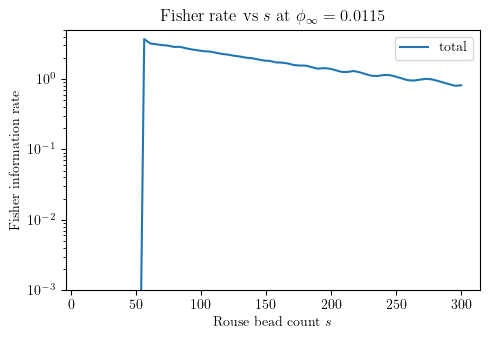

In [611]:
import json
import numpy as np
import matplotlib.pyplot as plt

path = "data/20260726/fisher_vs_rouse_s.json"
d = json.load(open(path))

runs = sorted(d["runs"], key=lambda r: r["s"])          # ascending in s
s    = np.array([r["s"] for r in runs])
phi  = np.array(runs[0]["phi_infs"])                     # concentration grid (same every run)

# each is (n_s, n_phi); n_phi = # of concentration points in phi_inf_values minus 2
f   = lambda key: np.array([[np.nan if v is None else v for v in r[key]] for r in runs])
fisher, esc, ret = f("fisher_rate"), f("fisher_rate_esc"), f("fisher_rate_ret")

j = 0                                                     # concentration column to plot (phi[j])
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(s, fisher[:, j],  label="total")
# ax.plot(s, esc[:, j],    label="escape")
# ax.plot(s, ret[:, j],    label="return")
ax.set(xlabel=r"Rouse bead count $s$", ylabel="Fisher information rate", yscale="log",
       title=fr"Fisher rate vs $s$ at $\phi_\infty={phi[j]:.4g}$")
ax.set_ylim(1e-3, 5)
ax.legend(); fig.tight_layout(); plt.show()


## Single sphere Fisher rate

0.001


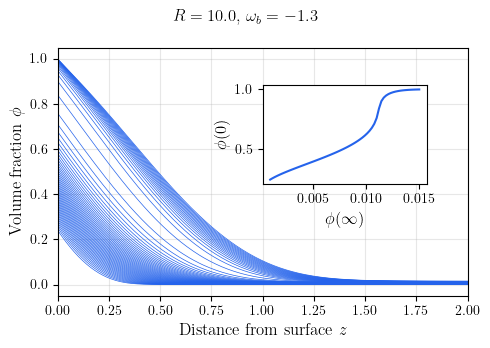

In [561]:
import json, numpy as np
import matplotlib.pyplot as plt

path = "data/20260723/demo_bvp_profiles.json"
d = json.load(open(path))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]

fig, ax = plt.subplots(figsize=(5, 3.5))
k = 0
ax.plot(z_full, phi_full.T, color="#2563EB", lw=0.5)
# ax.plot(z_full, phi_full[:k].T, color="#2563EB", lw=1)
# ax.plot(z_full, phi_full[k:].T, color="#EB2525", lw=1)
# ax.plot(z_lin,  phi_lin.T,  color="orange", lw=1, ls="--")
# ax.plot([], [], color="#2563EB", lw=1, label="profile")
# ax.plot([], [], color="orange", lw=1, ls="--", label="linear approx.")
ax.set_xlabel(r"Distance from surface $z$", fontsize=12)
ax.set_ylabel(r"Volume fraction $\phi$", fontsize=12)
ax.set_xlim(0, 2); ax.grid(alpha=0.3)

phi_surf = phi_full.T[0,:]
ins = ax.inset_axes(bounds = (0.5, 0.45, 0.4, 0.4))
ins.plot(phi_inf, phi_surf, color="#2563EB")
ins.set_xlabel(r"$\phi(\infty)$", fontsize=12)
ins.set_ylabel(r"$\phi(0)$", fontsize=12)

fig.suptitle(rf"$R={R}$, $\omega_b={omega_b}$")
fig.tight_layout()
print(phi_inf[k])

In [339]:
out_dir = "media/figures/20260723"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "concentration_profile_one_sphere_R_10_h0_-1.3.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260723/concentration_profile_one_sphere_R_10_h0_-1.3.pdf


### Surface concentration Fisher rate for a single sphere

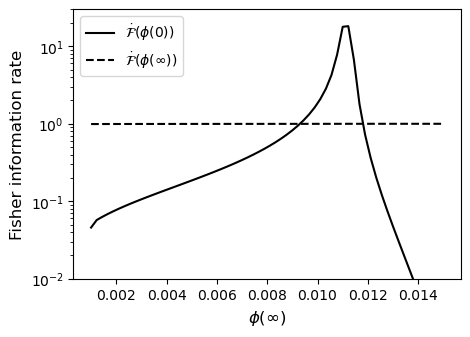

In [358]:
a = 1        # um
D_tf = 1e2      # um^2/s
kb = 4*a*D_tf 
ku = 1e0
tau = 1 / (kb*phi_surf) + 1 / ku
dphi_surf = np.gradient(phi_surf, phi_inf)
phi_surf_gain = (dphi_surf * phi_inf / phi_surf) ** 2

fisher_rate_one_sphere = phi_surf_gain / tau

fig, ax = plt.subplots(figsize=(5, 3.5))

ax.plot(phi_inf, fisher_rate_one_sphere, color="black",
        label=r"$\dot{\mathcal{F}}(\phi(0))$")
ax.plot(phi_inf, 1/tau, linestyle="dashed", color="black",
        label="$\dot{\mathcal{F}}(\phi(\infty))$")
ax.set_yscale('log')
ax.set_ylabel("Fisher information rate", fontsize=12)
ax.set_xlabel(r"$\phi(\infty)$", fontsize=12)
ax.set_ylim(1e-2, 30)
ax.legend()

In [346]:
out_dir = "media/figures/20260723"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fisher_rates_R_10_h0_-1.3.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260723/fisher_rates_R_10_h0_-1.3.pdf
